# Module 7 · Poisson processes and time-varying event rates
**Applied Stochastic Processes: Modeling, Simulation, and AI**

Practical question: **Can two event streams have the same daily count distribution but very different busy periods?**

Guided work: about 45–55 minutes. Exercises: about 25–35 minutes. This is **Concept Lab 4, Part A (week 7)**. Save these results and combine them with Module 8, Part B, as one lab due in week 8. Continue the existing course project.

[Course home](../index.html) · [Interactive lesson](../modules/module07.html) · [Project guide](../project-guide.html) · [Data provenance](../data/PROVENANCE.md)

Use **Restart Kernel and Run All** from the course root or `notebooks/`. No network, account, API key, or server is needed. Keep answers in the four marked exercise cells; worked examples do not supply those answers.

## 1. Count events over an interval
Let $N(t)$ count events in $(0,t]$, with $N(0)=0$. A **homogeneous Poisson process (HPP)** of rate $\lambda>0$ has independent increments over disjoint intervals and

$$N(t+h)-N(t)\sim\operatorname{Poisson}(\lambda h).$$

The increment law depends on duration $h$, not the starting time $t$: increments are **stationary**. Its mean and variance both equal $\lambda h$. The rate has units **events per hour** in the synthetic examples below; $\lambda h$ is an expected count, not a probability.

Independent increments do not mean the nested counts $N(t)$ and $N(t+h)$ are independent. They share all events before $t$. These are assumptions about the event process, not consequences of plotting a count histogram.

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import platform
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.stats import poisson
from scipy.special import gammaln
from IPython.display import display
SEED = 6231
plt.rcParams.update({"figure.figsize": (10, 3.8), "font.size": 11})

In [2]:
BREAKS = np.array([0.0, 1.0, 3.0, 4.0])
PROFILES = {"Flat": np.array([1.0, 1.0, 1.0]),
            "Middle peak": np.array([1/3, 5/3, 1/3]),
            "Late peak": np.array([1/3, 1/3, 3.0])}
BASE_RATE, REPLICAS = 6.0, 2000

def integrated_rate(start, end, rates, breaks=BREAKS):
    if not (breaks[0] <= start <= end <= breaks[-1]):
        raise ValueError("Use a window within the modeled horizon")
    overlap = np.maximum(0, np.minimum(end, breaks[1:])-np.maximum(start, breaks[:-1]))
    return float(np.dot(rates, overlap))

assert all(np.isclose(np.dot(w, np.diff(BREAKS)), 4) for w in PROFILES.values())

In [3]:
def simulate_events(rates, replicas=2000, seed=SEED, breaks=BREAKS):
    rates, breaks = np.asarray(rates, float), np.asarray(breaks, float)
    if (len(rates)+1 != len(breaks) or np.any(~np.isfinite(rates)) or np.any(rates < 0)
            or np.any(~np.isfinite(breaks)) or np.any(np.diff(breaks) <= 0)):
        raise ValueError("Use finite nonnegative rates and strictly increasing finite breaks")
    if int(replicas) != replicas or replicas < 1:
        raise ValueError("Use a positive integer number of replicas")
    rng = np.random.default_rng(seed)
    counts = rng.poisson(rates*np.diff(breaks), size=(replicas, len(rates)))
    paths = []
    for row in counts:
        events = [rng.uniform(a, b, int(n)) for a, b, n in zip(breaks[:-1], breaks[1:], row)]
        paths.append(np.sort(np.concatenate(events)))
    return counts, paths

### Exact simulation, without small time steps
In each constant-rate bin $[b_j,b_{j+1}]$, draw an independent count $K_j\sim\operatorname{Poisson}(\lambda_j(b_{j+1}-b_j))$. **Conditional on that count**, sample its event locations independently and uniformly inside the bin, then sort all events. Continuity makes endpoint conventions immaterial with probability one.

This is exact for the stated piecewise constant model. Sorting exactly 24 uniform points over four hours would instead fix the total count, removing its Poisson variation. For nonconstant rates, conditional event locations over the full horizon have density $\lambda(t)/\Lambda(4)$, not a uniform density.

Conditional on a fixed total, subinterval counts have a multinomial law and are dependent. Independent increments hold **before** conditioning on a total. All rates and event times here are synthetic, not reconstructed bike trips.

In [4]:
flat_rates = BASE_RATE*PROFILES["Flat"]
flat_counts, flat_paths = simulate_events(flat_rates, REPLICAS)
flat_total = flat_counts.sum(axis=1)
flat_mean_mcse = flat_total.std(ddof=1)/np.sqrt(REPLICAS)
flat_report = pd.Series({"exact mean and variance of N(4)": 4*BASE_RATE,
    "simulated mean": flat_total.mean(), "simulated variance": flat_total.var(ddof=1),
    "mean MCSE": flat_mean_mcse})
display(flat_report.round(6))
assert abs(flat_total.mean()-4*BASE_RATE) < 6*np.sqrt(4*BASE_RATE/REPLICAS)
assert all(np.all(np.diff(p) >= 0) and np.all((p >= 0) & (p <= 4)) for p in flat_paths)
assert np.array_equal(flat_counts, simulate_events(flat_rates, REPLICAS)[0])

exact mean and variance of N(4)    24.000000
simulated mean                     23.968000
simulated variance                 23.519736
mean MCSE                           0.108443
dtype: float64

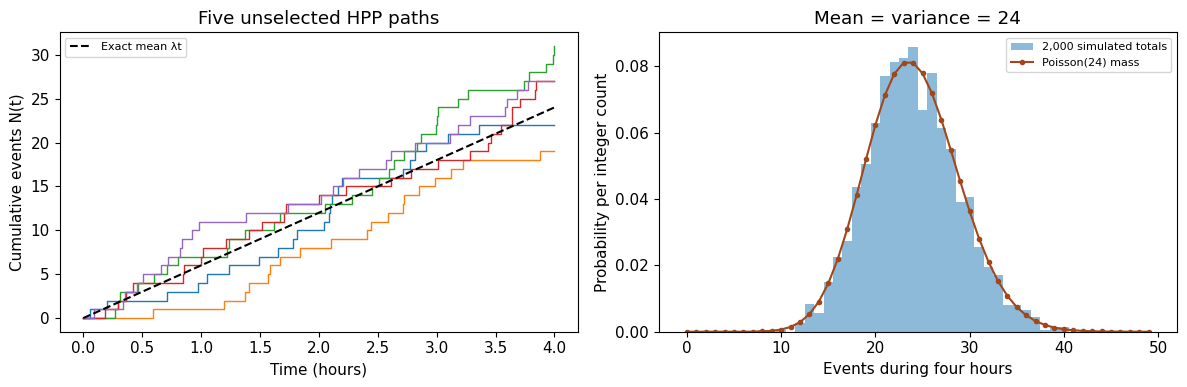

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for events in flat_paths[:5]:
    axes[0].step(np.r_[0, events, 4], np.r_[0, np.arange(1, len(events)+1), len(events)], where="post", lw=1)
axes[0].plot([0, 4], [0, 4*BASE_RATE], color="black", ls="--", label="Exact mean λt")
axes[0].set(xlabel="Time (hours)", ylabel="Cumulative events N(t)", title="Five unselected HPP paths")
axes[0].legend(fontsize=8)
k = np.arange(0, max(50, flat_total.max()+1))
axes[1].hist(flat_total, bins=np.arange(-0.5, k[-1]+1.5), density=True, alpha=0.5, label="2,000 simulated totals")
axes[1].plot(k, poisson.pmf(k, 4*BASE_RATE), color="#a0471c", marker=".", label="Poisson(24) mass")
axes[1].set(xlabel="Events during four hours", ylabel="Probability per integer count", title="Mean = variance = 24")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 2. Waiting times: rate versus scale
For an HPP, the time $W$ from a fixed time until the next event satisfies

$$P(W>w)=P(N(t+w)-N(t)=0)=e^{-\lambda w},\qquad E[W]=1/\lambda.$$

Successive complete interarrival times are iid exponential with **rate** $\lambda$. NumPy takes the **scale**, so use `rng.exponential(1/rate)`. At six events per hour, the mean gap is $1/6$ hour, or ten minutes.

The exponential law is memoryless: $P(W>s+h\mid W>s)=e^{-\lambda h}$. This is an HPP statement. Under time-varying rates, the next-event distribution depends on calendar time.

The next experiment draws independent **complete** exponential gaps directly. Pooling only gaps completed inside a fixed observation window selects against long gaps; the final censored gap is not zero and should not be silently dropped for a naive waiting-time fit.

In [6]:
WAIT_DRAWS = 20000
waits = np.random.default_rng(SEED+1).exponential(1/BASE_RATE, WAIT_DRAWS)
wait_mcse = waits.std(ddof=1)/np.sqrt(WAIT_DRAWS)
display(pd.Series({"exact mean gap (hours)": 1/BASE_RATE, "simulated mean gap": waits.mean(),
    "mean-gap MCSE": wait_mcse, "exact mean gap (minutes)": 60/BASE_RATE}).round(6))
assert abs(waits.mean()-1/BASE_RATE) < 6/(BASE_RATE*np.sqrt(WAIT_DRAWS))
wait_grid = np.linspace(0, 1, 100)
wait_survival = (waits[:, None] > wait_grid).mean(axis=0)

exact mean gap (hours)       0.166667
simulated mean gap           0.169350
mean-gap MCSE                0.001193
exact mean gap (minutes)    10.000000
dtype: float64

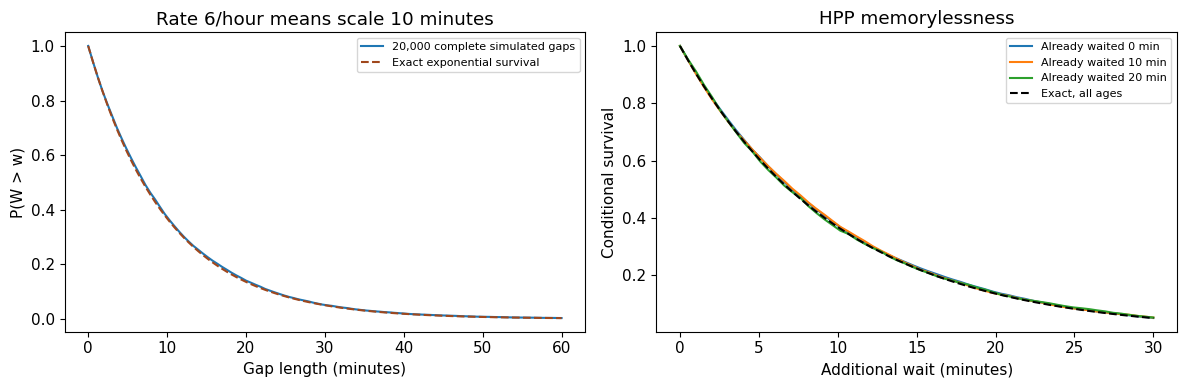

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(wait_grid*60, wait_survival, label="20,000 complete simulated gaps")
axes[0].plot(wait_grid*60, np.exp(-BASE_RATE*wait_grid), ls="--", color="#a0471c", label="Exact exponential survival")
axes[0].set(xlabel="Gap length (minutes)", ylabel="P(W > w)", title="Rate 6/hour means scale 10 minutes")
ages = [0, 1/6, 1/3]
remaining = np.linspace(0, 0.5, 60)
for age in ages:
    eligible = waits[waits > age]-age
    axes[1].plot(remaining*60, (eligible[:, None] > remaining).mean(axis=0), label=f"Already waited {age*60:g} min")
axes[1].plot(remaining*60, np.exp(-BASE_RATE*remaining), color="black", ls="--", label="Exact, all ages")
axes[1].set(xlabel="Additional wait (minutes)", ylabel="Conditional survival", title="HPP memorylessness")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 3. A changing clock: the nonhomogeneous Poisson process
For a deterministic, nonnegative intensity $\lambda(t)$, define cumulative intensity

$$\Lambda(t)=\int_0^t\lambda(u)\,du.$$

A **nonhomogeneous Poisson process (NHPP)** has independent increments with

$$N(t)-N(s)\sim\operatorname{Poisson}(\Lambda(t)-\Lambda(s)),\quad 0\le s<t.$$

Counts still have equal conditional-model mean and variance, but increments are generally **not stationary**: equal-length intervals can have different integrated intensities. For piecewise constant rates, integrate by overlap length rather than substituting the rate at the interval's left endpoint.

All three synthetic profiles below have a four-hour average of six events/hour. Their bin boundaries are $0,1,3,4$ hours. Flat rates are $(6,6,6)$, middle-peak rates $(2,10,2)$, and late-peak rates $(2,2,18)$. Every profile gives $N(4)\sim\operatorname{Poisson}(24)$, although its event timing differs. The daily bike counts do **not** identify any of these within-day profiles.

In [8]:
profile_runs, profile_rows = {}, []
for j, (name, weights) in enumerate(PROFILES.items()):
    rates = BASE_RATE*weights
    counts, paths = simulate_events(rates, REPLICAS, SEED+10+j)
    total = counts.sum(axis=1)
    profile_runs[name] = {"rates": rates, "counts": counts, "paths": paths}
    profile_rows.append([name, integrated_rate(0, 4, rates), total.mean(), total.var(ddof=1),
                         total.std(ddof=1)/np.sqrt(REPLICAS)])
    assert abs(total.mean()-24) < 6*np.sqrt(24/REPLICAS)
display(pd.DataFrame(profile_rows, columns=["profile", "exact mean and variance", "MC mean", "MC variance",
    "mean MCSE"]).set_index("profile").round(5))
time_grid = np.linspace(0, 4, 161)

,exact mean and variance,MC mean,MC variance,mean MCSE
profile,,,,
Flat,24.0,24.0245,23.67074,0.10879
Middle peak,24.0,24.2500,23.95248,0.10944
Late peak,24.0,23.9395,23.56562,0.10855


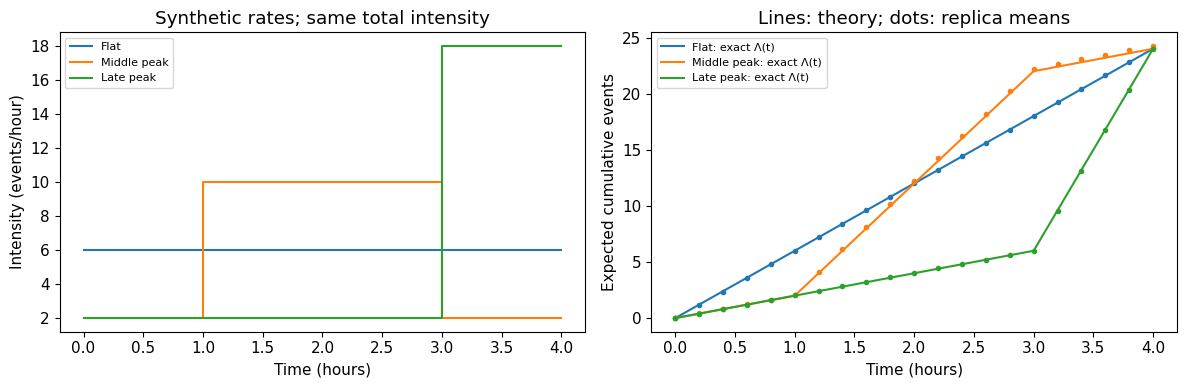

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, run in profile_runs.items():
    rates = run["rates"]
    axes[0].step(BREAKS, np.r_[rates, rates[-1]], where="post", label=name)
    cumulative = np.array([integrated_rate(0, t, rates) for t in time_grid])
    simulated = np.array([np.mean([np.searchsorted(p, t, side="right") for p in run["paths"]]) for t in time_grid])
    line, = axes[1].plot(time_grid, cumulative, label=f"{name}: exact Λ(t)")
    axes[1].plot(time_grid[::8], simulated[::8], ".", color=line.get_color())
axes[0].set(xlabel="Time (hours)", ylabel="Intensity (events/hour)", title="Synthetic rates; same total intensity")
axes[1].set(xlabel="Time (hours)", ylabel="Expected cumulative events", title="Lines: theory; dots: replica means")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### No event in a window that crosses a rate change
For the wait $W_s$ from a fixed time $s$, independent increments imply

$$P(W_s>h)=\exp\!\left(-\int_s^{s+h}\lambda(u)\,du\right).$$

The middle-peak window $(0.8,1.3]$ spans 0.2 hour at rate 2 and 0.3 hour at rate 10, giving integrated intensity **3.4** and no-event probability $e^{-3.4}\approx0.033373$. Using only the starting rate gives $e^{-2(0.5)}=e^{-1}\approx0.367879$, a very different answer.

Under an NHPP, surviving to a calendar time updates the relevant future intensity integral. Exponential memorylessness with a fixed rate does not apply across changes. Transforming time by $\Lambda$ is the useful connection to an HPP; the integrated intensity, rather than raw elapsed hours, is the event clock.

In [10]:
def count_in_window(paths, start, end):
    return np.array([np.searchsorted(p, end, side="right")-np.searchsorted(p, start, side="right") for p in paths])

WINDOW_START, WINDOW_LENGTH = 0.8, 0.5
middle = profile_runs["Middle peak"]
window_intensity = integrated_rate(WINDOW_START, WINDOW_START+WINDOW_LENGTH, middle["rates"])
window_counts = count_in_window(middle["paths"], WINDOW_START, WINDOW_START+WINDOW_LENGTH)
window_empty = (window_counts == 0).mean()
window_exact = np.exp(-window_intensity)
window_mcse = np.sqrt(window_empty*(1-window_empty)/REPLICAS)
display(pd.Series({"integrated intensity": window_intensity, "exact no-event probability": window_exact,
    "MC no-event probability": window_empty, "MCSE": window_mcse,
    "incorrect starting-rate shortcut": np.exp(-middle["rates"][0]*WINDOW_LENGTH)}).round(6))
assert np.isclose(window_intensity, 3.4)
assert abs(window_empty-window_exact) < 6*np.sqrt(window_exact*(1-window_exact)/REPLICAS)

integrated intensity                3.400000
exact no-event probability          0.033373
MC no-event probability             0.032000
MCSE                                0.003935
incorrect starting-rate shortcut    0.367879
dtype: float64

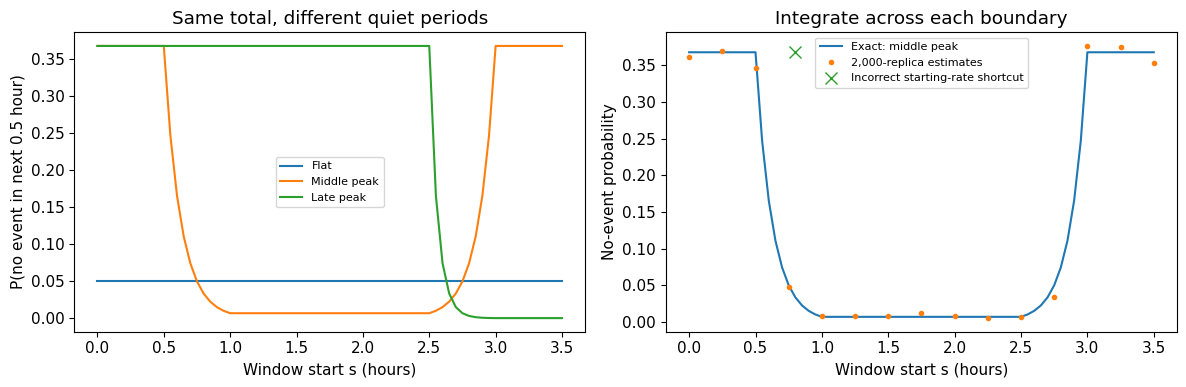

In [11]:
starts = np.linspace(0, 3.5, 71)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, run in profile_runs.items():
    empty_curve = [np.exp(-integrated_rate(s, s+0.5, run["rates"])) for s in starts]
    axes[0].plot(starts, empty_curve, label=name)
axes[0].set(xlabel="Window start s (hours)", ylabel="P(no event in next 0.5 hour)", title="Same total, different quiet periods")
axes[0].legend(fontsize=8)
mc_curve = [(count_in_window(middle["paths"], s, s+0.5) == 0).mean() for s in starts[::5]]
axes[1].plot(starts, [np.exp(-integrated_rate(s, s+0.5, middle["rates"])) for s in starts], label="Exact: middle peak")
axes[1].plot(starts[::5], mc_curve, ".", label="2,000-replica estimates")
axes[1].plot([0.8], [np.exp(-1)], "x", ms=9, label="Incorrect starting-rate shortcut")
axes[1].set(xlabel="Window start s (hours)", ylabel="No-event probability", title="Integrate across each boundary")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

Each no-event estimate uses independent replicas, so a binomial MCSE is appropriate at a fixed window. Estimates at different windows reuse paths and are correlated: the plot is not a collection of independent experiments or a simultaneous confidence band. A rare-event estimate of zero does not prove its true probability is zero.

**Verification before interpretation:** adding integrated intensities across adjacent intervals must recover the whole-horizon intensity; counts must agree with event times in each bin; and a zero rate must produce no events. A Poisson count law for one window alone does not establish the full process assumptions.

In [12]:
for name, run in profile_runs.items():
    rates, counts, paths = run["rates"], run["counts"], run["paths"]
    assert np.isclose(sum(integrated_rate(a, b, rates) for a, b in zip(BREAKS[:-1], BREAKS[1:])), 24)
    recovered = np.column_stack([count_in_window(paths, a, b) for a, b in zip(BREAKS[:-1], BREAKS[1:])])
    assert np.array_equal(recovered, counts)
zero_counts, zero_paths = simulate_events([0, 0, 0], 20)
assert zero_counts.sum() == 0 and all(len(p) == 0 for p in zero_paths)
assert np.isclose(integrated_rate(0.8, 1.3, middle["rates"]), 0.2*2+0.3*10)
print("Passed reproducibility, support, bin reconstruction, integrated-intensity, and zero-rate checks.")

Passed reproducibility, support, bin reconstruction, integrated-intensity, and zero-rate checks.


## 4. What can the bike-sharing counts calibrate?
The bundled UCI Bike Sharing observations (Fanaee-T, 2013; [DOI 10.24432/C5W894](https://doi.org/10.24432/C5W894), **CC BY 4.0**) contain 365 daily **completed-rental counts**. They do not contain trip timestamps, requested-but-unserved demand, or within-day exposure detail.

If $X_d$ is the full-day count, a provisional Poisson model specifies $X_d\sim\operatorname{Poisson}(\mu_d)$. Under a constant rate and one day of exposure per observation, the likelihood estimate is

$$\widehat\lambda=\frac{\sum_{d\in\mathrm{train}}X_d}{\sum_{d\in\mathrm{train}}1\text{ day}}.$$

A second model uses one rate for `workingday=0` and another for `workingday=1`, each estimated as its own total divided by its number of full days. The calendar class is known before the target day; `workingday=0` includes weekends and holidays. This is a **between-day calendar rate model**, not an inferred intraday profile.

Fit only January–August, freeze both rate estimates, then score all September–December days. These later observations are a **reused development holdout**, already inspected in earlier modules. The persistence baseline uses the previous observed day's count, beginning with August 31. It is a rolling one-day benchmark, not an open-loop four-month forecast.

In [13]:
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "data/bike_daily_2011.csv").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook inside the downloaded course folder.")
csv_path = ROOT / "data/bike_daily_2011.csv"
source = json.loads((ROOT / "data/source_metadata.json").read_text())
assert hashlib.sha256(csv_path.read_bytes()).hexdigest() == source["sample_sha256"]
bike = pd.read_csv(csv_path, parse_dates=["dteday"])
assert bike["dteday"].tolist() == pd.date_range("2011-01-01", "2011-12-31").tolist()
assert bike["cnt"].notna().all() and bike["cnt"].ge(0).all()
assert np.equal(bike["cnt"], np.floor(bike["cnt"])).all()
train = bike.loc[bike["dteday"] < "2011-09-01"].copy()
later = bike.loc[bike["dteday"] >= "2011-09-01"].copy()
assert len(train) == 243 and len(later) == 122

In [14]:
constant_rate = train["cnt"].sum()/len(train)
calendar_fit = train.groupby("workingday")["cnt"].agg(["sum", "count", "mean", "var"])
calendar_fit["variance / mean"] = calendar_fit["var"]/calendar_fit["mean"]
calendar_rates = calendar_fit["mean"]
actual = later["cnt"].to_numpy()
constant_prediction = np.full(len(later), constant_rate)
calendar_prediction = later["workingday"].map(calendar_rates).to_numpy()
persistence_prediction = bike["cnt"].shift(1).loc[later.index].to_numpy()
assert train["cnt"].sum() == 802684
assert calendar_fit["sum"].tolist() == [242853, 559831]
assert calendar_fit["count"].tolist() == [75, 168]
assert persistence_prediction[0] == train["cnt"].iloc[-1] == 5058
print(f"Constant rate: {constant_rate:.9f} completed rentals/day")
display(calendar_fit.round(6))

Constant rate: 3303.226337449 completed rentals/day


,sum,count,mean,var,variance / mean
workingday,,,,,
0,242853,75,3238.040000,2.689068e+06,830.461566
1,559831,168,3332.327381,2.026486e+06,608.129348


### Score predictions and challenge their uncertainty
The constant daily estimate is **3303.226337** completed rentals/day. Calendar rates are **3238.040000** for nonworking days and **3332.327381** for working days.

For prediction $\widehat\mu_d>0$, report point-prediction RMSE and a Poisson negative log score,

$$\mathrm{RMSE}=\sqrt{\frac1D\sum_d(X_d-\widehat\mu_d)^2},\qquad
\mathrm{NLL}=\frac1D\sum_d\{\widehat\mu_d-X_d\log\widehat\mu_d+\log(X_d!)\}.$$

Lower is better for both. NLL in natural-log units requires a **predictive distribution**. The constant and calendar models supply Poisson distributions; persistence supplies only a point forecast, so its NLL and Pearson entries are left blank. Compare persistence on RMSE.

Pearson residuals are $r_d=(X_d-\widehat\mu_d)/\sqrt{\widehat\mu_d}$. Under a correctly specified Poisson mean known in advance, $E[r_d^2]=1$. Their mean square here is a descriptive scale check, not a calibrated hypothesis test; fitting error, mean misspecification, dependence, and reuse of later data all matter.

In [15]:
predictions = {"Constant daily rate": constant_prediction,
               "Working-day calendar": calendar_prediction,
               "Persistence (point forecast)": persistence_prediction}
score_rows = []
for name, prediction in predictions.items():
    errors = actual-prediction
    rmse = np.sqrt(np.mean(errors**2))
    nll = np.mean(prediction-actual*np.log(prediction)+gammaln(actual+1)) if name != "Persistence (point forecast)" else np.nan
    pearson2 = np.mean(errors**2/prediction) if name != "Persistence (point forecast)" else np.nan
    score_rows.append([name, rmse, nll, pearson2])
scores = pd.DataFrame(score_rows, columns=["model", "RMSE", "mean Poisson NLL", "mean Pearson residual²"]).set_index("model")
display(scores.round(6).fillna("—"))
assert np.isclose(scores.iloc[0, 0], 1137.7008495601722)
assert np.isclose(scores.iloc[1, 1], 208.64022722744716)

,RMSE,mean Poisson NLL,mean Pearson residual²
model,,,
Constant daily rate,1137.700850,208.242036,391.848178
Working-day calendar,1138.770592,208.640227,394.532926
Persistence (point forecast),982.418265,—,—


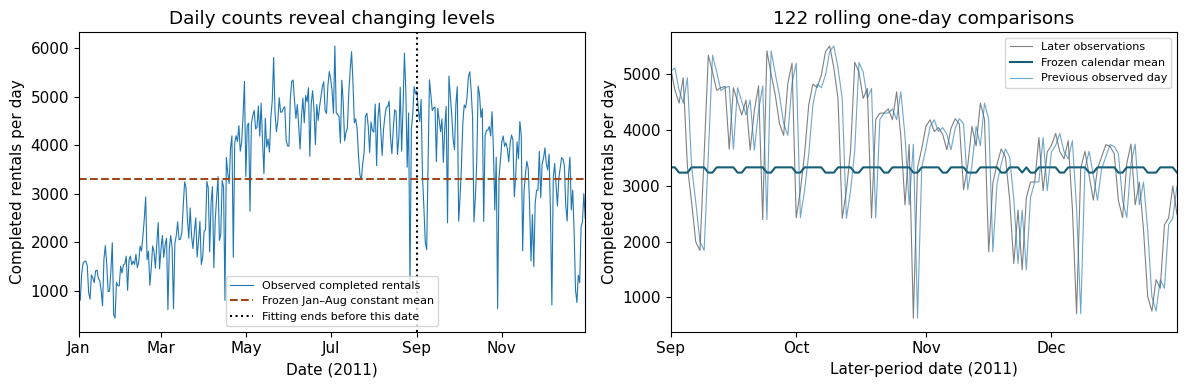

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(bike["dteday"], bike["cnt"], lw=0.8, label="Observed completed rentals")
axes[0].axhline(constant_rate, color="#a0471c", ls="--", label="Frozen Jan–Aug constant mean")
axes[0].axvline(pd.Timestamp("2011-09-01"), color="black", ls=":", label="Fitting ends before this date")
axes[0].set(xlabel="Date (2011)", ylabel="Completed rentals per day", title="Daily counts reveal changing levels", xlim=(bike["dteday"].min(), bike["dteday"].max()))
axes[1].plot(later["dteday"], actual, color="gray", lw=0.8, label="Later observations")
axes[1].plot(later["dteday"], calendar_prediction, color="#155e75", label="Frozen calendar mean")
axes[1].plot(later["dteday"], persistence_prediction, alpha=0.65, lw=0.8, label="Previous observed day")
axes[1].set(xlabel="Later-period date (2011)", ylabel="Completed rentals per day", title="122 rolling one-day comparisons", xlim=(later["dteday"].min(), later["dteday"].max()))
for ax in axes:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2 if ax is axes[0] else 1))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

### Heterogeneity is one explanation, not a complete repair
Pooling Poisson counts with different expected values can yield variance exceeding the mean. If a day is chosen at random and its mean is $M$, total variance gives

$$\operatorname{Var}(X)=E[M]+\operatorname{Var}(M).$$

Thus a large pooled variance-to-mean ratio alone does not distinguish changing means from other failures of a homogeneous Poisson model. But the ratios **within** the two training calendar classes are also enormous: approximately **830.46** for nonworking days and **608.13** for working days. This two-class calendar adjustment leaves substantial unexplained variation.

Later mean squared Pearson residuals are about **391.85** for the constant model and **394.53** for the calendar model, far above the unit Poisson reference. Persistence improves point RMSE; it does not supply a probability distribution or claim Poisson variation. These diagnostics do not prove a unique explanation. Seasonality, weather, dependence, other heterogeneity, and how completed rentals relate to demand require further investigation.

Aggregated counts can estimate integrated daily rates under assumptions. They cannot verify exponential interarrival times, resolve rush hours, or validate intraday independence. A daily average divided by 24 is an assumed hourly average; it is not evidence of a constant hourly rate.

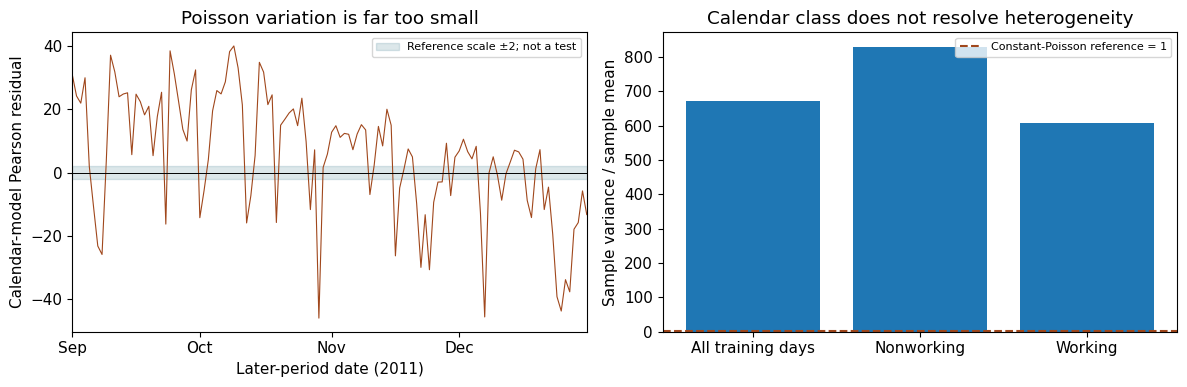

In [17]:
pooled_ratio = train["cnt"].var(ddof=1)/constant_rate
calendar_residual = (actual-calendar_prediction)/np.sqrt(calendar_prediction)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(later["dteday"], calendar_residual, color="#a0471c", lw=0.8)
axes[0].axhspan(-2, 2, color="#155e75", alpha=0.15, label="Reference scale ±2; not a test")
axes[0].axhline(0, color="black", lw=0.7)
axes[0].set(xlabel="Later-period date (2011)", ylabel="Calendar-model Pearson residual", title="Poisson variation is far too small", xlim=(later["dteday"].min(), later["dteday"].max()))
axes[0].xaxis.set_major_locator(mdates.MonthLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
axes[0].legend(fontsize=8)
axes[1].bar(["All training days", "Nonworking", "Working"], [pooled_ratio, *calendar_fit["variance / mean"]])
axes[1].axhline(1, color="#a0471c", ls="--", label="Constant-Poisson reference = 1")
axes[1].set(ylabel="Sample variance / sample mean", title="Calendar class does not resolve heterogeneity")
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

In [18]:
changed = bike.copy()
changed.loc[changed["dteday"] >= "2011-09-01", "cnt"] = 999999
changed_train = changed.loc[changed["dteday"] < "2011-09-01"]
assert changed_train["cnt"].mean() == constant_rate
assert changed_train.groupby("workingday")["cnt"].mean().equals(calendar_rates)
assert np.isclose(pooled_ratio, 672.8647676714046)
assert np.isclose(scores.iloc[0, 2], 391.8481783751199)
assert np.isclose(scores.iloc[1, 2], 394.5329264380307)
assert np.isclose(scores.iloc[2, 0], 982.418265068898)
print("Passed checksum, full calendar, frozen training exposure/rates, first predecessor,")
print("future-outcome noninterference, and independent score benchmarks.")

Passed checksum, full calendar, frozen training exposure/rates, first predecessor,
future-outcome noninterference, and independent score benchmarks.


## 5. Audit an AI-generated simulator
This pseudocode is intentionally flawed. Do not execute it as the model:

```python
rate = all_365_days.cnt.mean()       # fitted using later outcomes
waits = rng.exponential(rate, 2000)
p_no_event = exp(-rate_at(s) * h)
events = sort(rng.uniform(0, 4, 24)) # claimed middle-peak Poisson process
```

Check units, the fitting boundary, how a window crosses a rate change, and whether the count and timing laws are correct. A smooth plot or a plausible average does not verify a stochastic process. Require analytic benchmarks and checks that fail for the flawed alternatives. AI assistance is optional; disclose the assistance and the checks you performed.

## 6. Four short investigations — save for Concept Lab 4
### Exercise 1 — Rate, counts, and complete waits
For homogeneous rates **3 and 12 events/hour**, simulate **2,000 four-hour paths** and **20,000 independent complete exponential gaps**. Compare count means and variances with theory, and compare mean waits with theory; report the appropriate MCSE for each estimated mean. Explain why multiplying the rate by four divides the expected gap by four. Explain why pooling only gaps completed in a fixed window is a biased shortcut for this wait experiment.

In [19]:
# YOUR WORK — Exercise 1
# Add count/wait comparisons, mean MCSEs, and the finite-window explanation here.

### Exercise 2 — Equal totals, different busy periods
Keep the four-hour average at **6 events/hour** and compare the **middle-peak** and **late-peak** profiles. Derive $E[N(2)]$ and the no-event probability in **$(2.8,3.3]$**, then check both with **2,000 independent paths** and appropriate mean/proportion MCSEs. Explain why the distributions of $N(4)$ agree even though timing differs. Explain why fixing $N(4)=24$ destroys independent increments.

In [20]:
# YOUR WORK — Exercise 2
# Add integrated-intensity calculations, simulations, and conditioning reasoning here.

### Exercise 3 — Calibrate only what the observations support
Reproduce the **January–August-only** constant and working-day rates and their **September–December** RMSE and Poisson NLL. Compare persistence on **RMSE only**, explaining its use of the previous observed day and why a point forecast alone cannot receive a probability score. Report pooled and within-class training variance-to-mean ratios and later mean squared Pearson residuals. Explain which conclusions these diagnostics support and which event-time or intraday claims the daily counts cannot identify. Do not refit after viewing later outcomes.

In [21]:
# YOUR WORK — Exercise 3
# Add the frozen-fit comparison, dispersion interpretation, and observation limits here.

### Exercise 4 — Repair the AI audit
Audit all four lines in the flawed pseudocode: exponential parameterization, the integrated intensity across a boundary, fixed total and incorrect full-horizon uniform timing, and fitting on later outcomes. Repair the reasoning or code and give **at least two independent checks** that discriminate correct and incorrect models. State which event streams are synthetic and which observations are real. AI use is optional; disclose any assistance and how you checked it.

In [22]:
# YOUR WORK — Exercise 4
# Add corrected reasoning/code and discriminating verification evidence here.

## Reproducibility and next step
Python and the browser use different random generators, so individual paths need not match. Compare exact integrated intensities, distributions, Monte Carlo uncertainty, and observed-data calculations. The six figures above come from visible code and remain embedded in this executed notebook.

Module 8 will build on event rates to introduce continuous-time Markov chains. Keep Module 7 and Module 8 together as the single Concept Lab 4 submission due in week 8. For the sustained project, record what your observation resolution identifies before choosing a continuous-time model.

In [23]:
print("Python:", platform.python_version())
print({name: metadata.version(name) for name in ["numpy", "pandas", "scipy", "matplotlib"]})
print("Seed:", SEED, "| average synthetic rate per hour:", BASE_RATE, "| replicas:", REPLICAS)
print("Synthetic bin boundaries:", BREAKS, "| complete wait draws:", WAIT_DRAWS)
print("Data SHA-256:", hashlib.sha256(csv_path.read_bytes()).hexdigest())
print("Training: Jan–Aug, 243 full days; development: Sep–Dec, 122 one-day scores.")

Python: 3.10.9
{'numpy': '1.24.2', 'pandas': '2.0.0', 'scipy': '1.10.1', 'matplotlib': '3.7.1'}
Seed: 6231 | average synthetic rate per hour: 6.0 | replicas: 2000
Synthetic bin boundaries: [0. 1. 3. 4.] | complete wait draws: 20000
Data SHA-256: fb9790e24f07b237431b89c787a24ed8e97c365437a86f7161269df9452b2329
Training: Jan–Aug, 243 full days; development: Sep–Dec, 122 one-day scores.
